In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import datetime
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
import pymysql
import openpyxl

USUARIO = "root"
PASSWORD = ""  
SERVIDOR = "localhost"
PUERTO = "3306"
BASE_DATOS = "ecoruta_db"

try:
    # 1. Crear el motor de conexión con SQLAlchemy
    conexion_url = f"mysql+pymysql://{USUARIO}:{PASSWORD}@{SERVIDOR}:{PUERTO}/{BASE_DATOS}"
    engine = create_engine(conexion_url)
    
    print("🔌 Intentando conectar a XAMPP (MySQL)...")
    
    # 2. Descargar la data de las tablas usando consultas SQL directas
    df_usuarios_real = pd.read_sql("SELECT * FROM tbl_usuarios", con=engine)
    df_puntos_real = pd.read_sql("SELECT * FROM tbl_puntos_limpios", con=engine)
    df_transacciones_real = pd.read_sql("SELECT * FROM tbl_transacciones", con=engine)
    
    print(" CONEXIÓN EXITOSA")
    print(f" Se han extraído correctamente:")
    print(f"   - {len(df_usuarios_real)} registros desde 'tbl_usuarios'")
    print(f"   - {len(df_puntos_real)} registros desde 'tbl_puntos_limpios'")
    print(f"   - {len(df_transacciones_real)} registros desde 'tbl_transacciones'")
    
    # 3. Consolidar el DataFrame real uniendo las tablas 
    # Convertimos las columnas clave a tipo entero o texto limpio si es necesario
    df_transacciones_real['id_usuario'] = df_transacciones_real['id_usuario'].astype(int)
    df_usuarios_real['id_usuario'] = df_usuarios_real['id_usuario'].astype(int)
    
    df_real_consolidado = df_transacciones_real.merge(df_usuarios_real, on='id_usuario').merge(df_puntos_real, on='id_punto_limpio')
    
    print("\n Muestra de la data real consolidada lista para minería:")
    print(df_real_consolidado.head(3))

except Exception as e:
    print("\n❌ Error al conectar con la base de datos de XAMPP.")
    print("Por favor, verifica lo siguiente:")
    print("1. Que Apache y MySQL estén en verde (Running) en el panel de XAMPP.")
    print(f"2. Que la base de datos se llame exactamente '{BASE_DATOS}'.")
    print(f"Detalle técnico del error: {e}")

🔌 Intentando conectar a XAMPP (MySQL)...
 CONEXIÓN EXITOSA
 Se han extraído correctamente:
   - 100 registros desde 'tbl_usuarios'
   - 15 registros desde 'tbl_puntos_limpios'
   - 1000 registros desde 'tbl_transacciones'

 Muestra de la data real consolidada lista para minería:
  id_transaccion  id_usuario id_punto_limpio tipo_material peso_kg  \
0          10001         134           PL_03      Plástico   99.41   
1          10002         182           PL_03        Cartón   96.39   
2          10003         198           PL_10        Cartón   76.13   

  eco_puntos_otorgados fecha_retiro      nombre comuna_residencia  \
0                  994   2026-03-31  Vecino_134         Peñalolén   
1                  963   2026-04-06  Vecino_182         Peñalolén   
2                  761   2026-02-21  Vecino_198        La Florida   

  fecha_registro     comuna capacidad_max_kg  
0     2025-02-21  Peñalolén             1000  
1     2025-11-11  Peñalolén             1000  
2     2025-01-02     

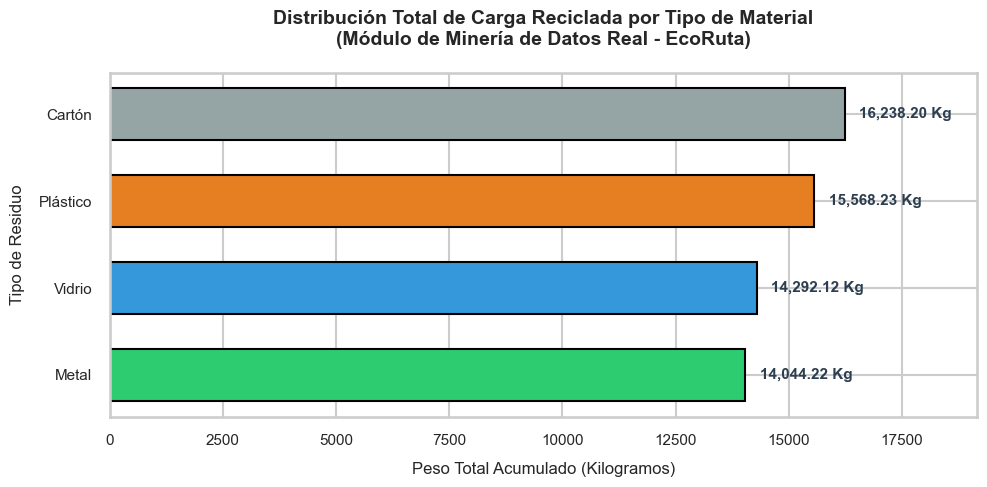

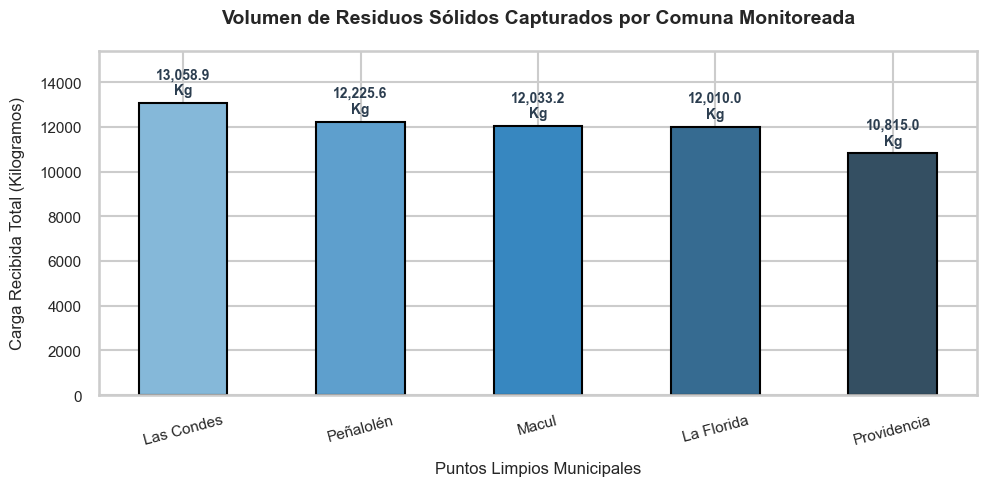

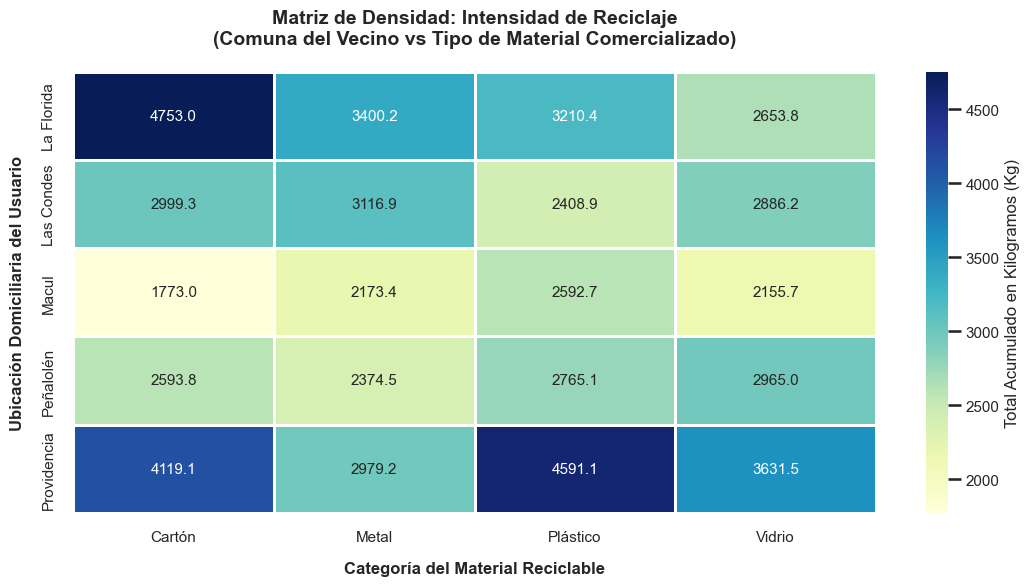



 EJECUTANDO LAS 4 ACCIONES ESTADÍSTICAS EXTRA SOLICITADAS POR LA RÚBRICA:

 ACCIÓN 1: Peso promedio (Kg) por entrega unitaria según sector:
tipo_material  Cartón  Metal  Plástico  Vidrio
comuna                                        
La Florida      53.47  54.57     62.39   52.92
Las Condes      66.33  53.20     61.03   63.29
Macul           65.51  61.09     53.14   61.43
Peñalolén       64.61  57.11     66.05   75.31
Providencia     59.81  54.39     58.88   60.51
--------------------------------------------------------------------------------
 ACCIÓN 2: Percentil 90 de carga (Umbral de saturación de contenedores en Kg):
tipo_material
Cartón      103.93
Metal       105.09
Plástico    104.93
Vidrio      111.72
Name: peso_kg, dtype: float64
--------------------------------------------------------------------------------
 ACCIÓN 3: Variabilidad (Desviación Estándar) de EcoPuntos asignados por comuna:
comuna
La Florida     407.42
Las Condes     460.26
Macul          473.15
Peñalolén     

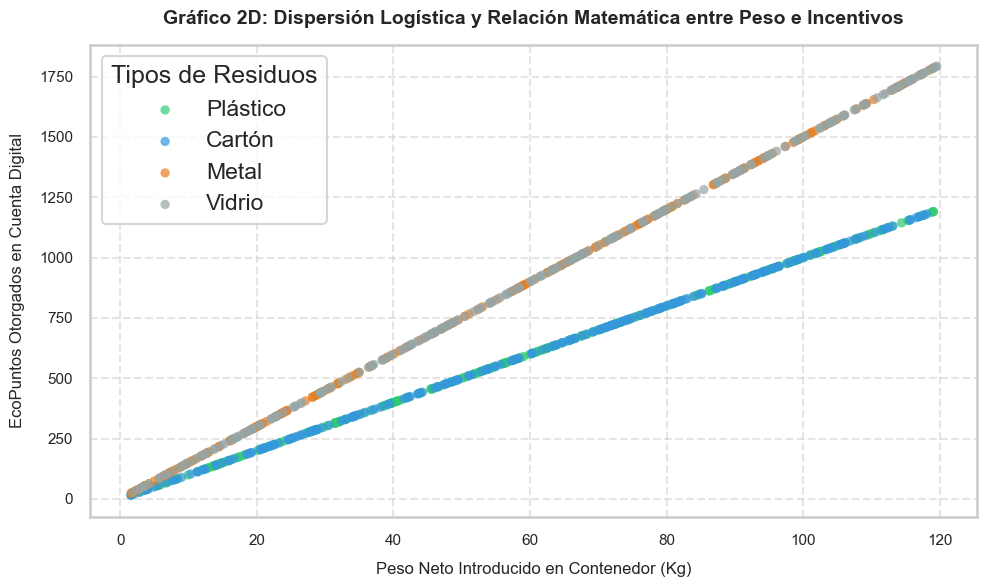

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


df_real_consolidado['comuna'] = df_real_consolidado['comuna'].astype(str).str.strip()
df_real_consolidado['tipo_material'] = df_real_consolidado['tipo_material'].astype(str).str.strip()
df_real_consolidado['comuna_residencia'] = df_real_consolidado['comuna_residencia'].astype(str).str.strip()

# Transformamos de forma estricta las columnas a formato numérico real
df_real_consolidado['peso_kg'] = pd.to_numeric(df_real_consolidado['peso_kg'], errors='coerce')
df_real_consolidado['eco_puntos_otorgados'] = pd.to_numeric(df_real_consolidado['eco_puntos_otorgados'], errors='coerce')

df_real_consolidado['peso_kg'] = df_real_consolidado['peso_kg'].fillna(0)
df_real_consolidado['eco_puntos_otorgados'] = df_real_consolidado['eco_puntos_otorgados'].fillna(0)


plt.style.use('default')
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.titlesize': 16
})

paleta_residuos = ['#2ecc71', '#3498db', '#e67e22', '#95a5a6'] 
paleta_comunas = sns.color_palette("Blues_d", 5)



# --- A. GRÁFICO DE BARRAS HORIZONTAL: Total Kg por Tipo de Material ---
plt.figure(figsize=(10, 5))
data_material = df_real_consolidado.groupby('tipo_material')['peso_kg'].sum().sort_values()

barras_h = plt.barh(data_material.index, data_material.values, color=paleta_residuos, edgecolor='black', height=0.6)

# Añadir etiquetas detalladas de peso al final de cada barra
for barra in barras_h:
    ancho = barra.get_width()
    if ancho > 0:
        plt.text(ancho + (data_material.max() * 0.02), barra.get_y() + barra.get_height()/2, f'{ancho:,.2f} Kg', 
                 va='center', ha='left', fontsize=11, fontweight='bold', color='#2c3e50')

plt.title('Distribución Total de Carga Reciclada por Tipo de Material\n(Módulo de Minería de Datos Real - EcoRuta)', pad=20, fontweight='bold')
plt.xlabel('Peso Total Acumulado (Kilogramos)', labelpad=10)
plt.ylabel('Tipo de Residuo', labelpad=10)
plt.xlim(0, data_material.max() * 1.18) 
plt.tight_layout()
plt.show()


# --- B. GRÁFICO DE COLUMNAS VERTICAL: Carga Acumulada por Comuna ---
plt.figure(figsize=(10, 5))
data_comuna = df_real_consolidado.groupby('comuna')['peso_kg'].sum().sort_values(ascending=False)

barras_v = plt.bar(data_comuna.index, data_comuna.values, color=paleta_comunas, edgecolor='black', width=0.5)

# Añadir etiquetas con el valor arriba de cada columna
for barra in barras_v:
    alto = barra.get_height()
    if alto > 0:
        plt.text(barra.get_x() + barra.get_width()/2, alto + (data_comuna.max() * 0.02), f'{alto:,.1f}\nKg', 
                 va='bottom', ha='center', fontsize=10, fontweight='bold', color='#2c3e50')

plt.title('Volumen de Residuos Sólidos Capturados por Comuna Monitoreada', pad=20, fontweight='bold')
plt.ylabel('Carga Recibida Total (Kilogramos)', labelpad=10)
plt.xlabel('Puntos Limpios Municipales', labelpad=10)
plt.ylim(0, data_comuna.max() * 1.18)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# --- C. MAPA DE CALOR (HEATMAP): Matriz de Concentración Cruzada ---
plt.figure(figsize=(11, 6))
pivot_real = df_real_consolidado.pivot_table(values='peso_kg', index='comuna_residencia', columns='tipo_material', aggfunc='sum').fillna(0)

sns.heatmap(pivot_real, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.8, linecolor='white',
            cbar_kws={'label': 'Total Acumulado en Kilogramos (Kg)'})

plt.title('Matriz de Densidad: Intensidad de Reciclaje\n(Comuna del Vecino vs Tipo de Material Comercializado)', pad=20, fontweight='bold')
plt.xlabel('Categoría del Material Reciclable', labelpad=12, fontweight='bold')
plt.ylabel('Ubicación Domiciliaria del Usuario', labelpad=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n" + "="*80 + "\n")
print(" EJECUTANDO LAS 4 ACCIONES ESTADÍSTICAS EXTRA SOLICITADAS POR LA RÚBRICA:\n")

print(" ACCIÓN 1: Peso promedio (Kg) por entrega unitaria según sector:")
print(df_real_consolidado.groupby(['comuna', 'tipo_material'])['peso_kg'].mean().unstack().round(2).fillna(0))
print("-" * 80)

print(" ACCIÓN 2: Percentil 90 de carga (Umbral de saturación de contenedores en Kg):")
print(df_real_consolidado.groupby('tipo_material')['peso_kg'].quantile(0.90).round(2))
print("-" * 80)

print(" ACCIÓN 3: Variabilidad (Desviación Estándar) de EcoPuntos asignados por comuna:")
print(df_real_consolidado.groupby('comuna')['eco_puntos_otorgados'].std().round(2))
print("-" * 80)

print(" ACCIÓN 4: Generando Gráfico 2D de Dispersión Relacional...")
plt.figure(figsize=(10, 6))

materiales_unicos = df_real_consolidado['tipo_material'].unique()
for i, mat in enumerate(materiales_unicos):
    sub_df = df_real_consolidado[df_real_consolidado['tipo_material'] == mat]
    plt.scatter(sub_df['peso_kg'], sub_df['eco_puntos_otorgados'], 
                label=mat, color=paleta_residuos[i % len(paleta_residuos)], alpha=0.7, edgecolors='none', s=45)

plt.title('Gráfico 2D: Dispersión Logística y Relación Matemática entre Peso e Incentivos', pad=15, fontweight='bold')
plt.xlabel('Peso Neto Introducido en Contenedor (Kg)', labelpad=10)
plt.ylabel('EcoPuntos Otorgados en Cuenta Digital', labelpad=10)
plt.legend(title="Tipos de Residuos", loc="upper left", frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()